In [1]:
from pathlib import Path
import sys


def _find_carl_project_root(start=Path.cwd()):
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate the project root from the notebook working directory.")


PROJECT_ROOT = _find_carl_project_root()
sys.path.insert(0, str(PROJECT_ROOT))


In [2]:
# In this notebook we select the value of the max lag by using the Multivariate Bayesian Information Criterion (BIC): 
# BIC = n * log(det(Sigma_hat)) + k * log(n)
# where Sigma_hat = 1/n *E^T * E with n = total number of time steps (reshaping time series as a unique vector), E = residual matrix of dimension n x D, where D is the number of child features
# k = number of estimated parameters (weights and incercepts)

In [3]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

In [4]:
data_dir = str(PROJECT_ROOT / "data" / "processed" / "TEP") + "/"
references_dir = str(PROJECT_ROOT / "references" / "TEP") + "/"
models_dir = str(PROJECT_ROOT / "models" / "TEP") + "/"
x_dir = models_dir + "max_lag_selection/X/"
y_dir = models_dir + "max_lag_selection/y/"
weights_dir = models_dir + "max_lag_selection/weights/"
y_pred_dir = models_dir + "max_lag_selection/y_pred/"

In [5]:
import os

for directory in [models_dir, x_dir, y_dir, weights_dir, y_pred_dir]:
    os.makedirs(directory, exist_ok=True)

In [6]:
training_file_name = "TEP_Training.parquet"
adjacency_matrix_file_name = "TEGroundTruth.txt"

In [7]:
df = pd.read_parquet(data_dir + training_file_name)

In [8]:
n_faultfree_samples = df[df["faultNumber"] == 0].shape[0]
df_faultfree = df.iloc[:n_faultfree_samples]
n_samples_per_ts = df[df["faultNumber"] == 0].groupby("simulationRun").size().max()
df_faultfree = df_faultfree.drop(["faultNumber", "simulationRun", "sample"], axis=1)

In [9]:
adjacency_matrix = np.loadtxt(references_dir + adjacency_matrix_file_name)

In [10]:
feature_names = df_faultfree.columns
n_features = len(feature_names)
child_parents_pairs = {}

for child_idx in range(n_features):
    parents = []
    for feature_idx in range(n_features):
        if adjacency_matrix[feature_idx, child_idx] == 1:
            parents.append(feature_names[feature_idx])
    child_parents_pairs[feature_names[child_idx]] = parents

In [11]:
max_lag_threshold = 19

In [12]:
for max_lag in range(1, max_lag_threshold + 1):
    for child, parents in child_parents_pairs.items():
        if len(parents) != 0:

            df_X = df_faultfree[parents + [child]]
            y = df_faultfree[child]

            df_X_lagged = pd.concat([df_X.shift(i).add_suffix(f"_lag{i}") for i in range(1, max_lag + 1)], axis=1)

            mask = []
            for ts_start_idx in range(0, n_faultfree_samples, n_samples_per_ts):
                mask.extend(range(ts_start_idx + max_lag, ts_start_idx + n_samples_per_ts))

            df_X_lagged = df_X_lagged.iloc[mask]
            y = y.iloc[mask]

            X = np.ones((df_X_lagged.shape[0], df_X_lagged.shape[1] + 1))
            X[:, 1:] = df_X_lagged.values
            y = y.to_numpy()

            beta, *_ = np.linalg.lstsq(X, y, rcond=None)

            np.save(x_dir + f"X_child_{child}_lag_{max_lag}.npy", X)
            np.save(y_dir + f"y_child_{child}_lag_{max_lag}.npy", y)
            np.save(weights_dir + f"beta_child_{child}_lag_{max_lag}.npy", beta)

In [13]:
n_ts = n_faultfree_samples // n_samples_per_ts
n_samples_max_lag_threshold = n_ts * (n_samples_per_ts - max_lag_threshold)

n_nodes_with_parents = sum([len(parents) != 0 for parents in child_parents_pairs.values()])

sample_cov_per_max_lag = {}
k_per_lag = {} # number of estimated parameters (weights and incercepts) per max lag

for max_lag in range(1, max_lag_threshold + 1):
    res = np.empty((n_samples_max_lag_threshold, n_nodes_with_parents))
    res_col_idx = 0
    k = 0

    pad = max_lag_threshold - max_lag

    for child, parents in child_parents_pairs.items():
        if len(parents) != 0:

            X = np.load(x_dir + f"X_child_{child}_lag_{max_lag}.npy")
            y = np.load(y_dir + f"y_child_{child}_lag_{max_lag}.npy")           
            beta = np.load(weights_dir + f"beta_child_{child}_lag_{max_lag}.npy")
            
            y_pred = X @ beta

            res_raw = y - y_pred

            n_samples_curr_lag_per_ts = y.shape[0] // n_ts

            res_2d = res_raw.reshape(n_ts, n_samples_curr_lag_per_ts)
            res_trimmed = res_2d[:, pad:].ravel()
            res[:, res_col_idx] = res_trimmed
            
            res_col_idx += 1

            k += len(beta)

            np.save(y_pred_dir + f"y_pred_child_{child}_lag_{max_lag}.npy", y_pred)

    sample_cov_per_max_lag[max_lag] = (res.T @ res) / n_samples_max_lag_threshold
    k_per_lag[max_lag] = k

In [14]:
bic_scores = pd.DataFrame(columns=["Max Lag", "BIC"])

for lag_max in range(1, max_lag_threshold + 1):
    sample_cov = sample_cov_per_max_lag[lag_max]
    k = k_per_lag[lag_max]
    bic = n_samples_max_lag_threshold * np.linalg.slogdet(sample_cov)[1] + k * np.log(n_samples_max_lag_threshold)
    bic_score = pd.DataFrame({
        "Max Lag": [lag_max],
        "BIC": [bic],
    })

    bic_scores = pd.concat(
        [bic_scores, bic_score], ignore_index=True)

bic_scores_sorted = bic_scores.sort_values(by=["BIC"], ascending=True).reset_index(drop=True)
display(bic_scores_sorted)
    

<ipykernel>\3612688201.py:12: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  bic_scores = pd.concat(


,Max Lag,BIC
0,1,-1.548234e+07
1,10,-1.522994e+07
2,9,-1.522925e+07
3,11,-1.522797e+07
4,16,-1.522606e+07
5,15,-1.522599e+07
6,14,-1.522202e+07
7,8,-1.522201e+07
8,12,-1.522150e+07
9,2,-1.521984e+07


Best BIC Score = -15482342.12123734 at Max Lag = 1


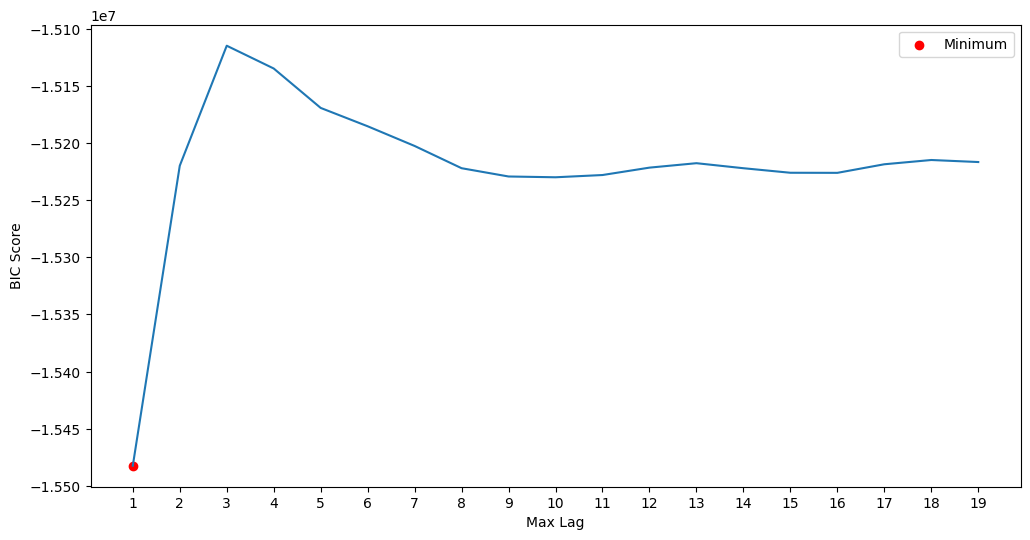

In [15]:
best_bic_score = bic_scores_sorted["BIC"][0]
best_max_lag = bic_scores_sorted["Max Lag"][0]

print(f"Best BIC Score = {best_bic_score} at Max Lag = {best_max_lag}")

plt.figure(figsize=(12, 6))
plt.plot(bic_scores["Max Lag"], bic_scores["BIC"])
plt.scatter(best_max_lag, best_bic_score, color="red", label="Minimum")
plt.xlabel("Max Lag")
plt.ylabel("BIC Score")
plt.xticks(range(1, max_lag_threshold + 1))
plt.legend()
plt.show()